In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import zscore, norm


df = pd.read_csv("../Files/diabetes.csv")
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [18]:

df["Glucose_Z"] = zscore(df["Glucose"])


In [19]:

outliers = df[abs(df["Glucose_Z"]) > 3]
print("Number of outliers = ", len(outliers))
print(outliers[["Glucose", "Glucose_Z"]])

Number of outliers =  5
     Glucose  Glucose_Z
75         0  -3.783654
182        0  -3.783654
342        0  -3.783654
349        0  -3.783654
502        0  -3.783654


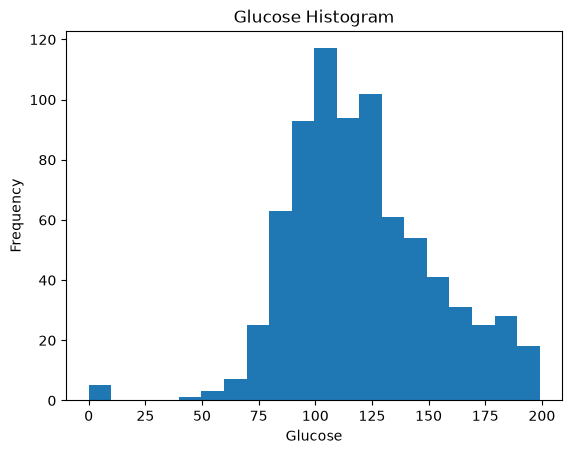

In [20]:
plt.hist(df["Glucose"],bins=20)
plt.xlabel("Glucose")
plt.ylabel("Frequency")
plt.title("Glucose Histogram")
plt.show()

In [10]:
## Probability calculation
x = 100
y = 140

mean = df["Glucose"].mean()
std = df["Glucose"].std()
print((f"\n Mean Glucose= {mean} "))
print(f"Std Glucose  = {std}")



 Mean Glucose= 120.89453125 
Std Glucose  = 31.97261819513622


In [11]:
between = df[(df["Glucose"] >= x) & (df["Glucose"] <= y)]
print(f"\nBetween {x} and {y}")
print(f"Count = {len(between)}")
print(f"Percentage = {len(between)/len(df)}*100")


Between 100 and 140
Count = 379
Percentage = 0.4934895833333333*100


In [14]:
p_between = norm.cdf(y,mean,std) - norm.cdf(x,mean,std)
print(f"Normal probability = {p_between}")

Normal probability = 0.46821958211558595


In [ ]:
# People with glucose up to x
up_to_x = df[df["Glucose"] <= x]
print("\n Up to ",x)
print(f"Count = {len(up_to_x)}")
print(f"Percentage = {len(up_to_x)/len(df)*100}")


 Up to  100
Count = 214
Percentage = 27.864583333333332


In [16]:
p_up_to_x = norm.cdf(x,mean,std)
print(f"Normal probability = {p_up_to_x}")

Normal probability = 0.256712708745466


In [21]:
above_x = df[df["Glucose"] > x]
print("\nabove" , x)
print("Count = ",len(above_x))
print("Percentage = " , len(above_x)/len(df)*100)


above 100
Count =  554
Percentage =  72.13541666666666


In [22]:
p_above_x = 1 - norm.cdf(x,mean,std)
print("Normal Probability = " ,p_above_x)

Normal Probability =  0.7432872912545341


In [23]:

## Exercise 1
df =  pd.read_csv("../Files/Sachin_Tendulkar.csv")
df


,Match_No,Innings,match_date,Versus,mode_of_dismissal,Runs,Balls_faced
0,1,1,1989-12-18 00:00:00,Pakistan,c Wasim Akram b Waqar Younis,0,2
1,2,2,1990-03-01 00:00:00,New Zealand,c & b S A Thomson,0,2
2,3,3,1990-03-06 00:00:00,New Zealand,c †I D S Smith b S A Thomson,36,39
3,4,4,1990-04-25 00:00:00,Sri Lanka,run out,10,12
4,5,5,1990-04-27 00:00:00,Pakistan,c Saeed Anwar b Imran Khan,20,25
...,...,...,...,...,...,...,...
447,459,448,2012-02-26 00:00:00,Australia,run out,14,15
448,460,449,2012-02-28 00:00:00,Sri Lanka,lbw b S L Malinga,39,30
449,461,450,2012-03-13 00:00:00,Sri Lanka,c D P M D Jayawardene b R A S Lakmal,6,19
450,462,451,2012-03-16 00:00:00,Bangladesh,c †Mushfiqur Rahim b Mashrafe Mortaza,114,147


In [24]:
runs = df["Runs"]
mean = runs.mean()
median = runs.median()
std = runs.std()
maxi = runs.max()
mini = runs.min()

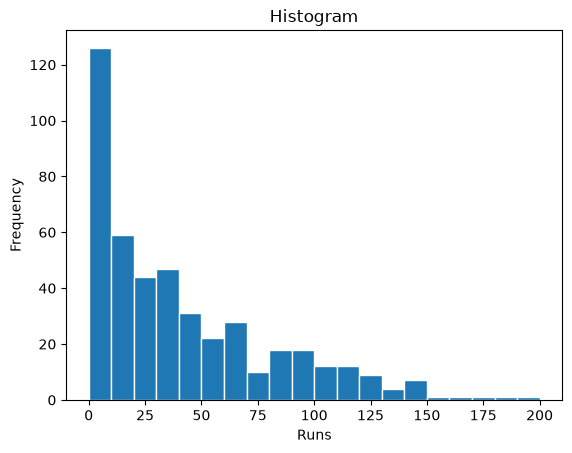

In [27]:
plt.hist(runs, bins=20, edgecolor="white")
plt.xlabel("Runs")
plt.ylabel("Frequency")
plt.title("Histogram")
plt.show()


In [28]:
#  Exercise 2

df["Z-score"] = (df["Runs"] - mean)/std
df

,Match_No,Innings,match_date,Versus,mode_of_dismissal,Runs,Balls_faced,Z-score
0,1,1,1989-12-18 00:00:00,Pakistan,c Wasim Akram b Waqar Younis,0,2,-1.018132
1,2,2,1990-03-01 00:00:00,New Zealand,c & b S A Thomson,0,2,-1.018132
2,3,3,1990-03-06 00:00:00,New Zealand,c †I D S Smith b S A Thomson,36,39,-0.119020
3,4,4,1990-04-25 00:00:00,Sri Lanka,run out,10,12,-0.768379
4,5,5,1990-04-27 00:00:00,Pakistan,c Saeed Anwar b Imran Khan,20,25,-0.518625
...,...,...,...,...,...,...,...,...
447,459,448,2012-02-26 00:00:00,Australia,run out,14,15,-0.668477
448,460,449,2012-02-28 00:00:00,Sri Lanka,lbw b S L Malinga,39,30,-0.044094
449,461,450,2012-03-13 00:00:00,Sri Lanka,c D P M D Jayawardene b R A S Lakmal,6,19,-0.868280
450,462,451,2012-03-16 00:00:00,Bangladesh,c †Mushfiqur Rahim b Mashrafe Mortaza,114,147,1.829058


In [29]:
outliers = df[df["Z-score"].abs() > 3]

outliers

,Match_No,Innings,match_date,Versus,mode_of_dismissal,Runs,Balls_faced,Z-score
218,226,219,1999-11-08 00:00:00,New Zealand,not out,186,150,3.627283
414,425,415,2009-03-08 00:00:00,New Zealand,retired hurt,163,133,3.052850
423,435,424,2009-11-05 00:00:00,Australia,c N M Hauritz b C J McKay,175,141,3.352554
430,442,431,2010-02-24 00:00:00,South Africa,not out,200,147,3.976938


In [31]:
print(f"Number of outliers : {len(outliers)}")

Number of outliers : 4


In [33]:
df[["Runs","Balls_faced","Z-score"]]

,Runs,Balls_faced,Z-score
0,0,2,-1.018132
1,0,2,-1.018132
2,36,39,-0.119020
3,10,12,-0.768379
4,20,25,-0.518625
...,...,...,...
447,14,15,-0.668477
448,39,30,-0.044094
449,6,19,-0.868280
450,114,147,1.829058


(array([126.,  59.,  44.,  47.,  31.,  22.,  28.,  10.,  18.,  18.,  12.,
         12.,   9.,   4.,   7.,   1.,   1.,   1.,   1.,   1.]),
 array([  0.,  10.,  20.,  30.,  40.,  50.,  60.,  70.,  80.,  90., 100.,
        110., 120., 130., 140., 150., 160., 170., 180., 190., 200.]),
 <BarContainer object of 20 artists>)

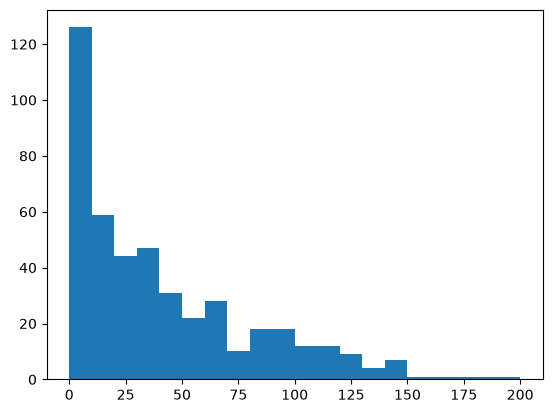

In [34]:
plt.hist(runs,bins=20)

{'whiskers': [<matplotlib.lines.Line2D at 0x20b7e488980>,
 'caps': [<matplotlib.lines.Line2D at 0x20b7e488c20>,
 'boxes': [<matplotlib.lines.Line2D at 0x20b7e488830>],
 'medians': [<matplotlib.lines.Line2D at 0x20b7e488ec0>],
 'fliers': [<matplotlib.lines.Line2D at 0x20b7e489010>],
 'means': []}

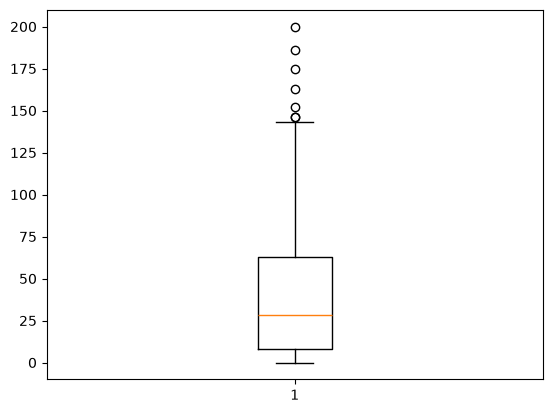

In [35]:
plt.boxplot(runs)

In [36]:
# Exercise 3

df["Z-Score Ball Faced"] = (df["Balls_faced"] - df["Balls_faced"].mean())/df["Balls_faced"].std()

In [37]:
df

,Match_No,Innings,match_date,Versus,mode_of_dismissal,Runs,Balls_faced,Z-score,Z-Score Ball Faced
0,1,1,1989-12-18 00:00:00,Pakistan,c Wasim Akram b Waqar Younis,0,2,-1.018132,-1.131368
1,2,2,1990-03-01 00:00:00,New Zealand,c & b S A Thomson,0,2,-1.018132,-1.131368
2,3,3,1990-03-06 00:00:00,New Zealand,c †I D S Smith b S A Thomson,36,39,-0.119020,-0.206724
3,4,4,1990-04-25 00:00:00,Sri Lanka,run out,10,12,-0.768379,-0.881464
4,5,5,1990-04-27 00:00:00,Pakistan,c Saeed Anwar b Imran Khan,20,25,-0.518625,-0.556589
...,...,...,...,...,...,...,...,...,...
447,459,448,2012-02-26 00:00:00,Australia,run out,14,15,-0.668477,-0.806493
448,460,449,2012-02-28 00:00:00,Sri Lanka,lbw b S L Malinga,39,30,-0.044094,-0.431637
449,461,450,2012-03-13 00:00:00,Sri Lanka,c D P M D Jayawardene b R A S Lakmal,6,19,-0.868280,-0.706531
450,462,451,2012-03-16 00:00:00,Bangladesh,c †Mushfiqur Rahim b Mashrafe Mortaza,114,147,1.829058,2.492238


In [38]:
ball_faced_outliers = df[df["Z-Score Ball Faced"].abs() > 3]
ball_faced_outliers

,Match_No,Innings,match_date,Versus,mode_of_dismissal,Runs,Balls_faced,Z-score,Z-Score Ball Faced


In [ ]:
'''
5 . Create a new column Runs_per_Ball = Runs/Balls_faced. Calculate its mean and standard deviation. Plot its histogram and boxplot . Identlify outliers using z-score. 

6. for x = 50 and y = 100, find the number and percentage of innings where Runs were between x and y . Using a normal distribution, calculate the probability using CDF(y) - CDF(x)

7. For x = 50, find the number and percentage of innings where Runs were up to x. Using a normal distribution, calculate the probability using CDF (x)

8. For x = 100 , Find the number and percnetage of innings where Runs were above x . Using a normal distribution, calcualte the probability using 1 - CDF(X)

9. Group the data by Versus and cal;cualte the mean Runs against each team. Display the teams in descending order of average runs and plot a bar chart.

10 . Identify innings where Runs >= 100 , Runs >= 50 and Runs == 0 . Calculate the number and percentage of innings in each category and plot a bar chart comparing the three categories
'''

'\n5 . Create a new column Runs_per_Ball = Runs/Balls_faced. Calculate its mean and standard deviation. Plot its histogram and boxplot . Identlify outliers using z-score. \n\n6. for x = 50 and y = 100, find the number and percentage of innings where Runs were between x and y . Using a normal distribution, calculate the probability using CDF(y) - CDF(x)\n\n7. For x = 50, find the number and percentage of innings where Runs were up to x. Using a normal distribution, calculate the probability using CDF (x)\n\n8. For x = 100 , Find the number and percnetage of innings where Runs were above x . Using a normal distribution, calcualte the probability using 1 - CDF(X)\n\n9. Group the data by Versus and cal;cualte the mean Runs against each team. Display the teams in descending order of\n'

In [43]:
# 5

df["Runs_per_Ball"] = df["Runs"] / df["Balls_faced"]
mean_RunnsPerBall = df["Runs_per_Ball"].mean()
std_RunsPerBall = df["Runs_per_Ball"].std()

(array([27., 13., 14., 20., 19., 42., 52., 52., 58., 47., 35., 27., 14.,
        17.,  4.,  4.,  5.,  1.,  0.,  1.]),
 array([0.        , 0.09827586, 0.19655172, 0.29482759, 0.39310345,
        0.49137931, 0.58965517, 0.68793103, 0.7862069 , 0.88448276,
        0.98275862, 1.08103448, 1.17931034, 1.27758621, 1.37586207,
        1.47413793, 1.57241379, 1.67068966, 1.76896552, 1.86724138,
        1.96551724]),
 <BarContainer object of 20 artists>)

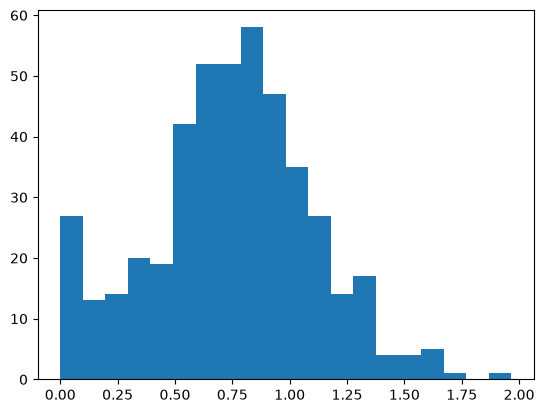

In [44]:
plt.hist(df["Runs_per_Ball"] , bins=20)

{'whiskers': [<matplotlib.lines.Line2D at 0x20b7e6c6510>,
 'caps': [<matplotlib.lines.Line2D at 0x20b7e6c67b0>,
 'boxes': [<matplotlib.lines.Line2D at 0x20b7e6c63c0>],
 'medians': [<matplotlib.lines.Line2D at 0x20b7e6c6a50>],
 'fliers': [<matplotlib.lines.Line2D at 0x20b7e6c6ba0>],
 'means': []}

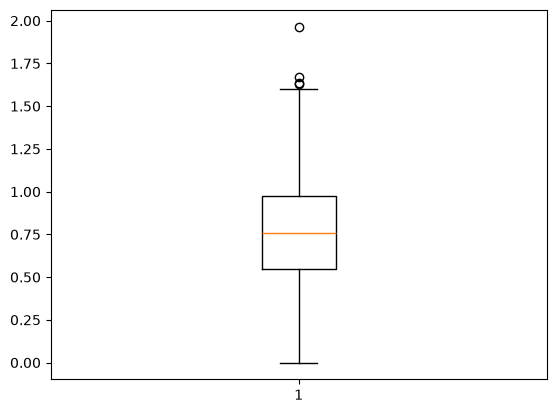

In [45]:
plt.boxplot(df["Runs_per_Ball"])

In [46]:
df["Z-score Runs per ball"] = (df["Runs_per_Ball"] - mean_RunnsPerBall) / std_RunsPerBall
df

,Match_No,Innings,match_date,Versus,mode_of_dismissal,Runs,Balls_faced,Z-score,Z-Score Ball Faced,Runs_per_Ball,Z-score Runs per ball
0,1,1,1989-12-18 00:00:00,Pakistan,c Wasim Akram b Waqar Younis,0,2,-1.018132,-1.131368,0.000000,-2.077403
1,2,2,1990-03-01 00:00:00,New Zealand,c & b S A Thomson,0,2,-1.018132,-1.131368,0.000000,-2.077403
2,3,3,1990-03-06 00:00:00,New Zealand,c †I D S Smith b S A Thomson,36,39,-0.119020,-0.206724,0.923077,0.493534
3,4,4,1990-04-25 00:00:00,Sri Lanka,run out,10,12,-0.768379,-0.881464,0.833333,0.243581
4,5,5,1990-04-27 00:00:00,Pakistan,c Saeed Anwar b Imran Khan,20,25,-0.518625,-0.556589,0.800000,0.150742
...,...,...,...,...,...,...,...,...,...,...,...
447,459,448,2012-02-26 00:00:00,Australia,run out,14,15,-0.668477,-0.806493,0.933333,0.522100
448,460,449,2012-02-28 00:00:00,Sri Lanka,lbw b S L Malinga,39,30,-0.044094,-0.431637,1.300000,1.543333
449,461,450,2012-03-13 00:00:00,Sri Lanka,c D P M D Jayawardene b R A S Lakmal,6,19,-0.868280,-0.706531,0.315789,-1.197872
450,462,451,2012-03-16 00:00:00,Bangladesh,c †Mushfiqur Rahim b Mashrafe Mortaza,114,147,1.829058,2.492238,0.775510,0.082534


In [47]:
outliers = df[df["Z-score Runs per ball"].abs() > 3]
outliers

,Match_No,Innings,match_date,Versus,mode_of_dismissal,Runs,Balls_faced,Z-score,Z-Score Ball Faced,Runs_per_Ball,Z-score Runs per ball
372,383,373,2007-03-19 00:00:00,Bermuda,not out,57,29,0.405463,-0.456627,1.965517,3.396919


### 6. for x = 50 and y = 100, find the number and percentage of innings where Runs were between x and y . Using a normal distribution, calculate the probability using CDF(y) - CDF(x)

In [ ]:
x = 50
y = 100

between_innings = df[(df["Runs"] >= x) & (df["Runs"] <= y)]
print(f"Number of innings in between {x} and {y} : {len(between_innings)}")
print(f"Percentage of innings : {(len(between_innings)/len(df))*100}")

Number of innings in between 50 and 100 : 51
Percentage of innings : 11.283185840707963


In [50]:
mean_runs = df["Runs"].mean()
std_runs = df["Runs"].std()

p_between = norm.cdf(y,mean_runs,std_runs) - norm.cdf(x, mean_runs, std_runs)
print(f"Normal Distribution : {p_between}")

Normal Distribution : 0.3392827468748292
